# Imbalanced Classification: a Fraud Detection Case Study

**What you'll learn**

- How to build an evaluation stack that survives 0.7% prevalence: PR-AUC, precision@k and
  recall at the **ops review budget** (analysts review $k$ alerts/day — the real constraint),
  and dollar-weighted value — and exactly *why* accuracy and even ROC-AUC flatter here.
- A controlled bake-off of the folk remedies — `scale_pos_weight`, random undersampling,
  random oversampling, and a from-scratch SMOTE — under **one frozen protocol**, with the
  senior finding shown honestly: with a strong boosted-tree learner nothing is
  transformative, SMOTE loses to naive duplication, and "mathematically equivalent"
  weighting vs oversampling diverge through implementation details you don't control.
- Why *every* rebalancing intervention destroys calibration, how to repair it (analytic
  prior correction, isotonic), and why the repaired probabilities are what the alerting
  policy actually consumes.
- How to choose the operating point that maximizes caught-fraud **dollars** within review
  capacity — ranking by $\hat p \times \text{amount}$ vs $\hat p$, and what to do when the
  budget, not the economics, binds.
- The three production realities that eat offline wins: label delay and maturation,
  selective labels (your own blocking erases your training signal), and adversarial drift.

**Why it matters in interviews**

- "You have 1% positives — walk me through your approach" is a stock senior screen. The
  reflexive answer ("SMOTE, then accuracy") is a junior tell; this notebook builds the
  evidence-backed answer.
- Fraud/abuse/risk case rounds revolve around the alert budget and asymmetric costs, not
  the classifier. Interviewers probe whether you optimize the *decision*.
- Selective labels and feedback loops separate candidates who have operated a live decision
  system from candidates who have only trained models on frozen CSVs.

## Setup

Everything runs on one simulated card-transaction dataset with **known ground truth**: we
keep the true fraud probability `p_true` for every transaction (evaluation only — no model
ever sees it). That gives us an oracle upper bound, a *feature ceiling* (the best any model
using our features could do), and exact knowledge of what each production pathology does.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import lightgbm as lgb
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)

## 1. The problem: 0.7% fraud, overlapping classes, a fixed review budget

One row = one card transaction over a 90-day window at a mid-size merchant
(~3,300 transactions/day). The label is confirmed fraud (chargeback). The generator hides
realistic structure in the true log-odds:

- classic fraud signals with **interactions**: new device × transaction burst, cross-border
  × night; a merchant-side risk score; young accounts; spend far above the customer's norm;
- **card-testing micro-charges**: transactions under \$2 carry elevated fraud odds — these
  frauds are nearly worthless in dollar terms, which will matter for the value-ranking
  section;
- three pure-noise features (`session_seconds`, `cart_items`, `pct_weekend`) — real fraud
  feature stores are full of these;
- a latent term (fraud signal no feature captures): even the Bayes-optimal oracle is far
  from perfect. **Class overlap is the norm** — plenty of legitimate transactions look
  fraud-ish and vice versa. A fraud model with AUC ≈ 0.999 usually means leakage
  ([02_leakage_validation.ipynb](02_leakage_validation.ipynb)), not brilliance.

The base rate is ~0.7% — inside the 0.5–1% band typical of card-not-present fraud.

In [2]:
N = 300_000
N_DAYS = 90
FRAUD_RATE = 0.007

COEF = {
    "new_device": 2.2, "cross_border": 1.2, "ship_bill_mismatch": 2.0,
    "merchant_risk": 50.0, "log_txn24": 0.6, "burst": 1.6,
    "amount_ratio": 1.1, "night": 0.8, "cb_night": 1.2,
    "device_burst": 1.8, "log_amount": 0.45, "micro": 2.2,
    "account_age": -0.55, "latent_sd": 1.0,
}


def simulate_transactions(n, rng, coef=COEF, fraud_rate=FRAUD_RATE):
    """Card transactions with known true fraud probability per row."""
    hour_probs = np.array([1.0, 0.7, 0.5, 0.4, 0.4, 0.5, 1.0, 2.0, 3.5, 4.5, 5.0, 5.5,
                           6.0, 6.0, 5.8, 5.5, 5.5, 5.8, 6.2, 6.5, 6.0, 5.0, 3.5, 2.0])
    hour_probs = hour_probs / hour_probs.sum()
    day = rng.integers(0, N_DAYS, n)                      # metadata, not a feature
    hour = rng.choice(24, size=n, p=hour_probs)
    amount = np.round(np.exp(rng.normal(3.4, 1.1, n)), 2)  # median ~$30, heavy right tail
    merchant_risk = rng.beta(1.1, 45, n)                   # merchant's historical fraud rate
    account_age_days = np.minimum(rng.gamma(1.8, 400, n), 3000).astype(int)
    txn_24h = rng.poisson(1.2, n)                          # card velocity, last 24h
    amount_over_avg = np.exp(rng.normal(0, 0.6, n))        # amount / customer trailing avg
    new_device = rng.binomial(1, 0.06, n)
    cross_border = rng.binomial(1, 0.08, n)
    ship_bill_mismatch = rng.binomial(1, 0.04, n)
    session_seconds = rng.gamma(2, 90, n)                  # noise
    cart_items = rng.poisson(2.1, n) + 1                   # noise
    pct_weekend = rng.beta(2, 3, n)                        # noise
    night = (hour <= 5).astype(int)

    z_signal = (
        coef["new_device"] * new_device
        + coef["cross_border"] * cross_border
        + coef["ship_bill_mismatch"] * ship_bill_mismatch
        + coef["merchant_risk"] * merchant_risk
        + coef["log_txn24"] * np.log1p(txn_24h)
        + coef["burst"] * (txn_24h >= 4)
        + coef["amount_ratio"] * np.clip(np.log(amount_over_avg), -1.5, 2.5)
        + coef["night"] * night
        + coef["cb_night"] * cross_border * night          # cross-border at 3am
        + coef["device_burst"] * new_device * (txn_24h >= 3)
        + coef["log_amount"] * np.clip(np.log(amount / 30), -2, 3)
        + coef["micro"] * (amount < 2.0)                   # card-testing micro-charges
        + coef["account_age"] * np.log1p(account_age_days / 30)
    )
    z = z_signal + rng.normal(0, coef["latent_sd"], n)     # unobservable fraud signal
    b0 = brentq(lambda b: expit(b + z).mean() - fraud_rate, -25, 10)
    p_true = expit(b0 + z)
    is_fraud = rng.binomial(1, p_true)
    return pd.DataFrame({
        "amount": amount, "hour": hour, "merchant_risk": merchant_risk,
        "account_age_days": account_age_days, "txn_24h": txn_24h,
        "amount_over_avg": amount_over_avg, "new_device": new_device,
        "cross_border": cross_border, "ship_bill_mismatch": ship_bill_mismatch,
        "session_seconds": session_seconds, "cart_items": cart_items,
        "pct_weekend": pct_weekend, "day": day,
        "is_fraud": is_fraud, "p_true": p_true, "z_signal": z_signal,
    })


df = simulate_transactions(N, rng)
y_all = df["is_fraud"].to_numpy()
print(f"n = {len(df):,}   fraud rate = {y_all.mean():.4f}   n_fraud = {y_all.sum():,}")
print(f"oracle (uses latent) : ROC-AUC {roc_auc_score(y_all, df['p_true']):.3f}   "
      f"PR-AUC {average_precision_score(y_all, df['p_true']):.3f}")
print(f"feature ceiling      : ROC-AUC {roc_auc_score(y_all, df['z_signal']):.3f}   "
      f"PR-AUC {average_precision_score(y_all, df['z_signal']):.3f}")
print(f"fraud share of $     : {df.loc[y_all == 1, 'amount'].sum() / df['amount'].sum():.2%}")

n = 300,000   fraud rate = 0.0069   n_fraud = 2,077
oracle (uses latent) : ROC-AUC 0.954   PR-AUC 0.380


feature ceiling      : ROC-AUC 0.934   PR-AUC 0.304
fraud share of $     : 1.03%


Two reference points we will hold every model against:

- **oracle**: ranks by the true `p_true` (includes the latent term no feature captures) —
  the Bayes ceiling;
- **feature ceiling**: ranks by the true signal computable from our features — the best any
  model *trained on these features* can converge to.

Even the oracle's PR-AUC is ~0.38–0.40: at 0.7% prevalence with heavy class overlap, most
alerts are false even for a perfect model. Calibrate your expectations *before* modeling —
a candidate who promises 0.9 precision at high recall here has not done fraud.

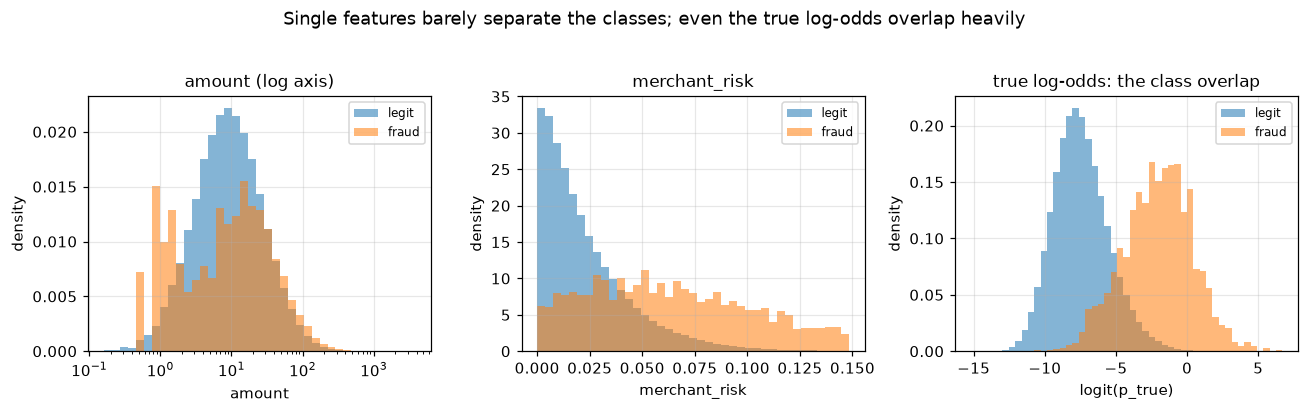

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col, tt, logx in [
    (axes[0], "amount", "amount (log axis)", True),
    (axes[1], "merchant_risk", "merchant_risk", False),
]:
    bins = (np.geomspace(df[col].min() + 0.01, df[col].max(), 40) if logx
            else np.linspace(0, df[col].quantile(0.999), 40))
    ax.hist(df.loc[y_all == 0, col], bins=bins, density=True, alpha=0.55, label="legit")
    ax.hist(df.loc[y_all == 1, col], bins=bins, density=True, alpha=0.55, label="fraud")
    if logx:
        ax.set_xscale("log")
    ax.set(title=tt, xlabel=col, ylabel="density")
    ax.legend(fontsize=8)
lo = logit(df["p_true"])
bins = np.linspace(lo.min(), lo.max(), 50)
axes[2].hist(lo[y_all == 0], bins=bins, density=True, alpha=0.55, label="legit")
axes[2].hist(lo[y_all == 1], bins=bins, density=True, alpha=0.55, label="fraud")
axes[2].set(title="true log-odds: the class overlap", xlabel="logit(p_true)", ylabel="density")
axes[2].legend(fontsize=8)
fig.suptitle("Single features barely separate the classes; even the true log-odds overlap heavily", y=1.03)
fig.tight_layout()
plt.show()

### Splits and the baseline learner

Train / validation / test = 150k / 50k / 100k, **stratified** on the label so each split
holds its share of the ~2,100 frauds. Stratification is legitimate here because the
generator is stationary; in production fraud you use *time-based* splits — patterns drift
and labels mature over time (sections 6.1 and 6.3;
[02_leakage_validation.ipynb](02_leakage_validation.ipynb) covers the split-design
arguments). The validation split does double duty: early stopping and, later,
recalibration. The test split is touched only by the frozen evaluation protocol.

The learner is a modestly tuned LightGBM
([01_gradient_boosting_mastery.ipynb](01_gradient_boosting_mastery.ipynb)) with early
stopping on validation PR-AUC. One gotcha worth knowing: `eval_metric` **adds** your metric
to the objective's default (binary log loss) rather than replacing it, and
`lgb.early_stopping` halts when *any* metric stalls. For weighted models the unweighted
validation log loss degrades from iteration 1, silently stopping training almost
immediately. `first_metric_only=True` makes early stopping watch PR-AUC alone — without it,
several models below would quietly train for ~1 iteration.

In [4]:
FEATURES = ["amount", "hour", "merchant_risk", "account_age_days", "txn_24h",
            "amount_over_avg", "new_device", "cross_border", "ship_bill_mismatch",
            "session_seconds", "cart_items", "pct_weekend"]
assert "p_true" not in FEATURES and "z_signal" not in FEATURES and "day" not in FEATURES

df_pool, df_te = train_test_split(df, test_size=1 / 3, stratify=df["is_fraud"], random_state=42)
df_tr, df_va = train_test_split(df_pool, test_size=0.25, stratify=df_pool["is_fraud"], random_state=42)
y_tr = df_tr["is_fraud"].to_numpy()
y_va = df_va["is_fraud"].to_numpy()
y_te = df_te["is_fraud"].to_numpy()
amt_te = df_te["amount"].to_numpy()

LGB_PARAMS = dict(
    n_estimators=600, learning_rate=0.06, num_leaves=31, min_child_samples=60,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, deterministic=True, force_row_wise=True, verbose=-1, n_jobs=2,
)


def fit_lgbm(X, y, sample_weight=None, **extra):
    """Fit LightGBM with early stopping on validation PR-AUC (metric-only, see note above)."""
    m = lgb.LGBMClassifier(**{**LGB_PARAMS, **extra})
    m.fit(X, y, sample_weight=sample_weight,
          eval_X=df_va[FEATURES], eval_y=y_va, eval_metric="average_precision",
          callbacks=[lgb.early_stopping(40, verbose=False, first_metric_only=True),
                     lgb.log_evaluation(0)])
    return m


def score_test(m, d=None):
    return m.predict_proba((df_te if d is None else d)[FEATURES])[:, 1]


m_base = fit_lgbm(df_tr[FEATURES], y_tr)
s_base = score_test(m_base)
print(f"train {len(df_tr):,} ({y_tr.sum()} fraud) | valid {len(df_va):,} ({y_va.sum()}) "
      f"| test {len(df_te):,} ({y_te.sum()})")
print(f"baseline: {m_base.best_iteration_} trees")

train 150,000 (1039 fraud) | valid 50,000 (346) | test 100,000 (692)
baseline: 75 trees


## 2. Evaluation first: metrics that survive 0.7% prevalence

Before touching any imbalance "remedy", we fix how success is measured. Getting this order
wrong is the classic failure: teams compare interventions on metrics that can't see the
problem, pick the wrong one, and ship it.

### 2.1 Accuracy is a broken compass, and ROC-AUC hides the alert flood

In [5]:
acc_all_negative = ((np.zeros_like(y_te)) == y_te).mean()
acc_model = ((s_base >= 0.5).astype(int) == y_te).mean()
print(f"accuracy, predict 'nobody is fraud' : {acc_all_negative:.4f}")
print(f"accuracy, LightGBM @ threshold 0.5  : {acc_model:.4f}")
print(f"frauds caught by 'nobody is fraud'  : 0 of {y_te.sum()}")

accuracy, predict 'nobody is fraud' : 0.9931
accuracy, LightGBM @ threshold 0.5  : 0.9932
frauds caught by 'nobody is fraud'  : 0 of 692


99.3% accuracy while catching zero fraud: at extreme imbalance accuracy measures the
prevalence, not the model. ROC-AUC fails more subtly. It is a fine *ranking* statistic
(probability a random fraud outscores a random legit transaction) and is prevalence-
invariant — which is exactly the problem: the FPR axis is normalized by ~99,300 negatives,
so an FPR that looks tiny is still an overwhelming number of false alerts. The
ROC → precision translation at prevalence $\pi$
(derived in [03_evaluation_calibration.ipynb](03_evaluation_calibration.ipynb)):
$\text{precision} = \pi\,\text{TPR} / (\pi\,\text{TPR} + (1-\pi)\text{FPR})$.

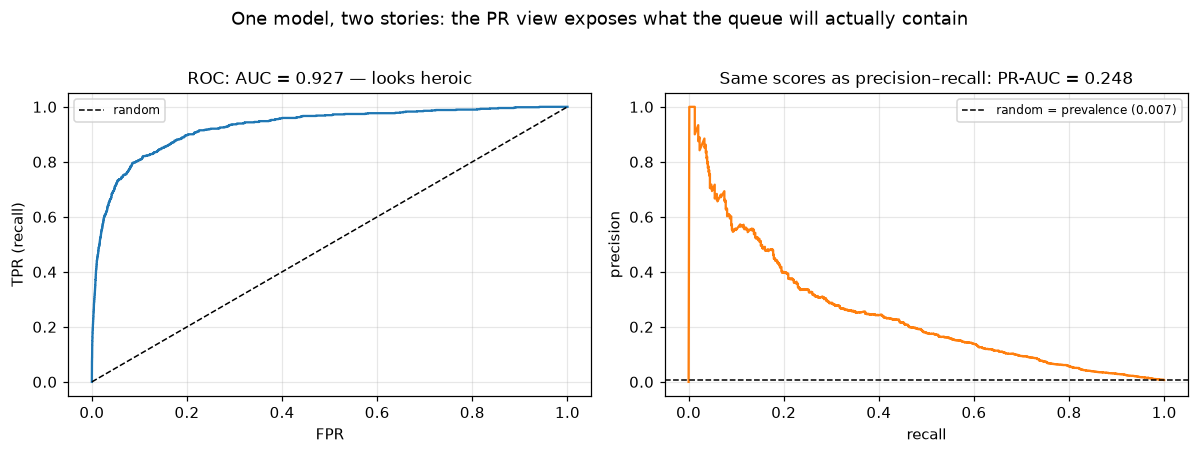

to reach 80% recall: FPR = 0.092  ->  ~108 alerts/day, precision 0.057


In [6]:
fpr, tpr, thr = roc_curve(y_te, s_base)
prec_grid = (y_te.mean() * tpr) / (y_te.mean() * tpr + (1 - y_te.mean()) * fpr + 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr, "C0")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[0].set(title=f"ROC: AUC = {roc_auc_score(y_te, s_base):.3f} — looks heroic",
            xlabel="FPR", ylabel="TPR (recall)")
axes[0].legend(fontsize=8)
axes[1].plot(tpr, prec_grid, "C1")
axes[1].axhline(y_te.mean(), color="k", ls="--", lw=1, label=f"random = prevalence ({y_te.mean():.3f})")
axes[1].set(title=f"Same scores as precision–recall: PR-AUC = {average_precision_score(y_te, s_base):.3f}",
            xlabel="recall", ylabel="precision")
axes[1].legend(fontsize=8)
fig.suptitle("One model, two stories: the PR view exposes what the queue will actually contain", y=1.02)
fig.tight_layout()
plt.show()

i80 = np.searchsorted(tpr, 0.80)
alerts_day_80 = (fpr[i80] * (1 - y_te.mean()) + 0.80 * y_te.mean()) * len(y_te) / N_DAYS
print(f"to reach 80% recall: FPR = {fpr[i80]:.3f}  ->  ~{alerts_day_80:.0f} alerts/day, "
      f"precision {prec_grid[i80]:.3f}")

An "AUC 0.93" model needs a multi-percent FPR to reach 80% recall — dozens of alerts per
day at single-digit precision. Whether that is viable depends entirely on a number that
appears in no ML textbook metric: **how many alerts the fraud-ops team can review**.

### 2.2 The review budget is the real constraint

Our ops team reviews **10 alerts/day** at ~\$5 of analyst time each; a reviewed fraud is
stopped (we recover the transaction amount), a missed fraud costs its amount in chargeback.
Over the 90-day test window that is a budget of $k = 900$ alerts. The metrics that map to
this reality:

- **precision@k** — hit rate inside the queue (analyst experience, trust in the system);
- **recall@budget** — share of fraud *events* caught within capacity;
- **\$-recall@budget** — share of fraud *dollars* caught: fraud losses are billed in
  dollars, and amounts vary by ~3 orders of magnitude;
- **net value** — dollars saved minus review cost. The metric the CFO reads.

PR-AUC remains the best single *ranking* summary (it integrates precision over all
budgets), but decisions get made at the budget point. We freeze this protocol now — every
intervention in section 3 is scored by exactly this function on the untouched test set.

In [7]:
C_REVIEW = 5.0
REVIEWS_PER_DAY = 10
K_BUDGET = REVIEWS_PER_DAY * N_DAYS           # 900 alerts over the test window
TOTAL_FRAUD_DOLLARS = (amt_te * y_te).sum()


def protocol(s, k=K_BUDGET):
    """Frozen evaluation: ranking metrics + ops metrics at the review budget."""
    top = np.argsort(-s, kind="stable")[:k]
    caught_dollars = (amt_te[top] * y_te[top]).sum()
    return {
        "ROC-AUC": roc_auc_score(y_te, s),
        "PR-AUC": average_precision_score(y_te, s),
        "precision@900": y_te[top].mean(),
        "recall@900": y_te[top].sum() / y_te.sum(),
        "$recall@900": caught_dollars / TOTAL_FRAUD_DOLLARS,
        "net value $": caught_dollars - C_REVIEW * k,
    }


base_table = pd.DataFrame({
    "baseline LightGBM": protocol(s_base),
    "feature ceiling (truth from X)": protocol(df_te["z_signal"].to_numpy()),
    "oracle (true p, incl. latent)": protocol(df_te["p_true"].to_numpy()),
}).T
print(base_table.round(3).to_string())
print(f"\ntest window: {N_DAYS} days x {len(df_te) / N_DAYS:,.0f} txns/day; "
      f"budget {REVIEWS_PER_DAY}/day -> k = {K_BUDGET}; total fraud $ {TOTAL_FRAUD_DOLLARS:,.0f}")

                                ROC-AUC  PR-AUC  precision@900  recall@900  $recall@900  net value $
baseline LightGBM                 0.927   0.248          0.260       0.338        0.359     16726.73
feature ceiling (truth from X)    0.936   0.316          0.326       0.423        0.480     23872.48
oracle (true p, incl. latent)     0.956   0.395          0.366       0.475        0.516     26059.32

test window: 90 days x 1,111 txns/day; budget 10/day -> k = 900; total fraud $ 59,171


The baseline catches roughly a third of fraud (and a slightly larger share of fraud
dollars) inside a 10-alert/day budget, at ~26% queue precision. The gap to the feature
ceiling (~0.32 PR-AUC) is the *maximum* any training trick can recover; the gap from
ceiling to oracle is irreducible without new features. Keep those two gaps separate in your
head — interventions below fight over the first, smaller one.

How much of a metric difference is real? With 692 test frauds, PR-AUC has meaningful
sampling noise — bootstrap it before you celebrate improvements
([../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb)).

In [8]:
boot_pr = np.empty(200)
idx_all = np.arange(len(y_te))
for b in range(200):
    bi = rng.choice(idx_all, len(idx_all), replace=True)
    boot_pr[b] = average_precision_score(y_te[bi], s_base[bi])
ci = np.quantile(boot_pr, [0.025, 0.975])
print(f"baseline PR-AUC = {average_precision_score(y_te, s_base):.3f}, "
      f"bootstrap 95% CI [{ci[0]:.3f}, {ci[1]:.3f}]  (width {ci[1] - ci[0]:.3f})")

baseline PR-AUC = 0.248, bootstrap 95% CI [0.213, 0.283]  (width 0.071)


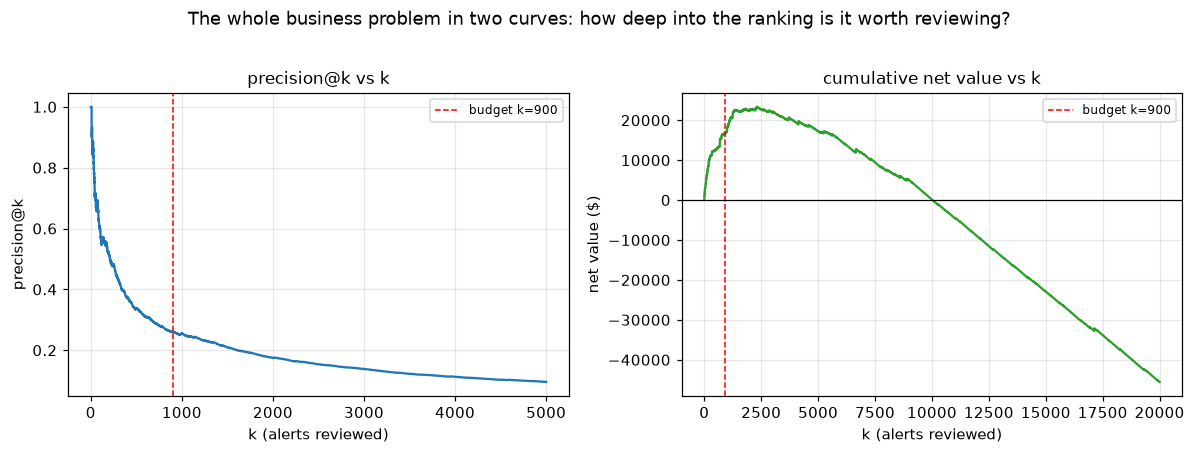

In [9]:
order = np.argsort(-s_base, kind="stable")
cum_pos = np.cumsum(y_te[order])
ks = np.arange(1, len(y_te) + 1)
cum_value = np.cumsum(amt_te[order] * y_te[order]) - C_REVIEW * ks

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks[:5000], cum_pos[:5000] / ks[:5000], "C0")
axes[0].axvline(K_BUDGET, color="red", ls="--", lw=1, label=f"budget k={K_BUDGET}")
axes[0].set(title="precision@k vs k", xlabel="k (alerts reviewed)", ylabel="precision@k")
axes[0].legend(fontsize=8)
axes[1].plot(ks[:20000], cum_value[:20000], "C2")
axes[1].axvline(K_BUDGET, color="red", ls="--", lw=1, label=f"budget k={K_BUDGET}")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(title="cumulative net value vs k", xlabel="k (alerts reviewed)", ylabel="net value ($)")
axes[1].legend(fontsize=8)
fig.suptitle("The whole business problem in two curves: how deep into the ranking is it worth reviewing?", y=1.02)
fig.tight_layout()
plt.show()

## 3. The rebalancing bake-off, under one frozen protocol

The folk remedies for imbalance, in the order people usually reach for them:

1. **`scale_pos_weight`** (cost-sensitive weighting): multiply the positive-class loss by
   $w$. We test the folk default $w = n_{neg}/n_{pos} \approx 143$ and a moderate
   $w \approx 16$ chosen to match an effective 10% prevalence.
2. **Random undersampling**: throw away negatives until fraud is 10% of the training set.
3. **Random oversampling**: duplicate fraud rows until they are 10%.
4. **SMOTE**: synthesize fraud rows by interpolating between minority nearest neighbors.
   `imblearn` is one `pip install` away, but the algorithm is ~10 lines — implementing it
   demystifies what it can and cannot add.

The protocol, frozen for every contender: identical features, identical hyperparameters,
resampling applied to the **training split only**, early stopping on the same *untouched*
validation split, scoring by `protocol()` on the same untouched test split. (Resampling
validation or test data is a leakage bug we demonstrate in the Pitfalls section.)

In [10]:
def smote_synthesize(X_pos, n_synth, rng, k=5):
    """Vanilla SMOTE: neighbors on standardized minority rows, interpolate in raw space."""
    mu, sd = X_pos.mean(axis=0), X_pos.std(axis=0) + 1e-9
    nn = NearestNeighbors(n_neighbors=k + 1).fit((X_pos - mu) / sd)
    _, nbr_idx = nn.kneighbors((X_pos - mu) / sd)
    base = rng.integers(0, len(X_pos), n_synth)
    nbr = nbr_idx[base, rng.integers(1, k + 1, n_synth)]   # skip col 0 (self)
    lam = rng.random((n_synth, 1))
    return X_pos[base] + lam * (X_pos[nbr] - X_pos[base])


TARGET_PREV = 0.10
pos_idx = np.where(y_tr == 1)[0]
neg_idx = np.where(y_tr == 0)[0]

# undersample: keep enough negatives for 10% prevalence
n_neg_keep = int(len(pos_idx) * (1 - TARGET_PREV) / TARGET_PREV)
keep_neg = rng.choice(neg_idx, n_neg_keep, replace=False)
us_idx = np.concatenate([pos_idx, keep_neg])
R_KEEP = n_neg_keep / len(neg_idx)                        # negative keep-rate

# oversample: duplicate positives up to 10% prevalence
n_pos_target = int(len(neg_idx) * TARGET_PREV / (1 - TARGET_PREV))
os_pos = rng.choice(pos_idx, n_pos_target, replace=True)
os_idx = np.concatenate([neg_idx, os_pos])
M_OVER = n_pos_target / len(pos_idx)                      # duplication factor

# SMOTE: same target prevalence with synthetic positives
X_tr_np = df_tr[FEATURES].to_numpy(dtype=float)
n_synth = n_pos_target - len(pos_idx)
X_synth = smote_synthesize(X_tr_np[pos_idx], n_synth, rng)
X_smote = pd.DataFrame(np.vstack([X_tr_np, X_synth]), columns=FEATURES)
y_smote = np.concatenate([y_tr, np.ones(n_synth, dtype=int)])

# matched weight: same effective prevalence as the resamplers
prev = y_tr.mean()
W_MATCH = (TARGET_PREV / (1 - TARGET_PREV)) / (prev / (1 - prev))
W_FULL = len(neg_idx) / len(pos_idx)

print(f"undersampled train: {len(us_idx):,} rows (keep rate r = {R_KEEP:.3f})")
print(f"oversampled train : {len(os_idx):,} rows (positives duplicated x{M_OVER:.1f})")
print(f"SMOTE train       : {len(X_smote):,} rows ({n_synth:,} synthetic positives)")
print(f"weights           : matched w = {W_MATCH:.1f}, folk default w = {W_FULL:.1f}")
print("\na synthetic 'transaction' (note the fractional flags and impossible combos):")
print(pd.DataFrame(X_synth[:3], columns=FEATURES).round(3).to_string(index=False))

undersampled train: 10,390 rows (keep rate r = 0.063)
oversampled train : 165,512 rows (positives duplicated x15.9)
SMOTE train       : 165,512 rows (15,512 synthetic positives)
weights           : matched w = 15.9, folk default w = 143.4

a synthetic 'transaction' (note the fractional flags and impossible combos):
 amount   hour  merchant_risk  account_age_days  txn_24h  amount_over_avg  new_device  cross_border  ship_bill_mismatch  session_seconds  cart_items  pct_weekend
 56.155 21.495          0.091           206.243    1.495            0.967         0.0           0.0                 1.0          157.055       3.505        0.467
 86.135 16.368          0.074           663.910    1.000            2.796         1.0           0.0                 0.0          253.558       1.316        0.397
119.817 12.818          0.161           331.941    1.000            2.630         0.0           0.0                 0.0          103.755       3.883        0.561


Look at the synthetic rows: `new_device = 0.4`, fractional cross-border flags,
non-integer velocity counts. SMOTE assumes minority points are dense enough that linear
interpolation between neighbors stays on the data manifold. With ~1,000 positives in 12
mixed continuous/binary dimensions, it mostly is not — SMOTE manufactures transactions
that cannot exist and labels them fraud.

In [11]:
runs = {"baseline": (m_base, s_base)}
for name, kwargs, data in [
    (f"weight w={W_MATCH:.0f} (matched 10%)", {"scale_pos_weight": W_MATCH}, None),
    (f"weight w={W_FULL:.0f} (folk default)", {"scale_pos_weight": W_FULL}, None),
    ("undersample -> 10%", {}, (df_tr[FEATURES].iloc[us_idx], y_tr[us_idx])),
    ("oversample -> 10%", {}, (df_tr[FEATURES].iloc[os_idx], y_tr[os_idx])),
    ("SMOTE -> 10%", {}, (X_smote, y_smote)),
]:
    X_fit, y_fit = (df_tr[FEATURES], y_tr) if data is None else data
    m = fit_lgbm(X_fit, y_fit, **kwargs)
    runs[name] = (m, score_test(m))

bakeoff = pd.DataFrame({name: protocol(s) for name, (m, s) in runs.items()}).T
bakeoff["mean pred"] = [s.mean() for _, s in runs.values()]
bakeoff["trees"] = [m.best_iteration_ for m, _ in runs.values()]
print(bakeoff.round(3).to_string())

                             ROC-AUC  PR-AUC  precision@900  recall@900  $recall@900  net value $  mean pred  trees
baseline                       0.927   0.248          0.260       0.338        0.359     16726.73      0.007     75
weight w=16 (matched 10%)      0.899   0.164          0.242       0.315        0.323     14594.86      0.036    173
weight w=143 (folk default)    0.903   0.172          0.236       0.306        0.313     14019.28      0.072    280
undersample -> 10%             0.928   0.246          0.291       0.379        0.400     19149.34      0.057     79
oversample -> 10%              0.930   0.280          0.301       0.392        0.422     20466.39      0.050     88
SMOTE -> 10%                   0.925   0.248          0.286       0.371        0.390     18570.31      0.014    159


### Reading the table honestly

- **Nothing is transformative.** Every intervention lands within a few PR-AUC points of
  the baseline — against a bootstrap CI ~0.07 wide and a feature-ceiling gap of the same
  order. The folklore ("imbalance must be fixed before training") is not what the data
  says: the boosted trees handle 0.7% prevalence fine.
- **Random over/undersampling** eke out a small edge on this dataset (a couple of PR-AUC
  points, a few recall points at the budget). Real, but of the same size as retuning one
  hyperparameter on the baseline — and, as the next cell shows, partly noise.
- **SMOTE loses to naive duplication.** All that neighbor geometry performs *worse* than
  copying rows — consistent with what large benchmark studies find for strong learners
  (Elor & Averbuch-Elor 2022, "To SMOTE, or not to SMOTE?"): with boosted trees, balancing
  rarely helps, and SMOTE's synthetic points can actively mislead. SMOTE was designed in
  2002 around weak, distance-based learners; its assumptions do not survive contact with
  mixed-type tabular data.
- **Cost-sensitive weighting is the worst performer here** — at *both* the folk-default
  and the matched weight, and note the folk default trained 3–6x longer to get there. Also
  note `mean pred`: every intervention except the baseline predicts an average fraud
  probability of 1.5%–30% against a true 0.7% — section 4 is about that damage.

**The weighting-vs-oversampling asymmetry deserves a senior-level pause.** In the loss
function, duplicating a positive 16 times and weighting it 16x are *identical*. The
outcomes are not (we verified this is not the row-count regularizer `min_child_samples`,
and passing the same weights via `sample_weight` gives yet another number). The loss-level
equivalence is broken by implementation details — histogram binning, bagging of duplicated
rows, early-stopping dynamics — that you do not control and that differ across libraries
and versions. That is the actual senior lesson: **treat every rebalancing knob as an
empirical hyperparameter to validate under your frozen protocol, never as a principle that
transfers.** Anyone who tells you "weighting ≡ oversampling, so pick either" is reasoning
about a model that is not the one being fit.

### Is the resampling edge even real? Re-run with different seeds

In [12]:
seed42_scores = {
    "baseline": s_base,
    "oversample -> 10%": runs["oversample -> 10%"][1],
    f"weight w={W_MATCH:.0f}": runs[f"weight w={W_MATCH:.0f} (matched 10%)"][1],
}
stab_rows = {}
for name, kwargs, data in [
    ("baseline", {}, None),
    ("oversample -> 10%", {}, (df_tr[FEATURES].iloc[os_idx], y_tr[os_idx])),
    (f"weight w={W_MATCH:.0f}", {"scale_pos_weight": W_MATCH}, None),
]:
    X_fit, y_fit = (df_tr[FEATURES], y_tr) if data is None else data
    row = {}
    for seed in (42, 43, 44):
        s = (seed42_scores[name] if seed == 42
             else score_test(fit_lgbm(X_fit, y_fit, random_state=seed, **kwargs)))
        top = np.argsort(-s, kind="stable")[:K_BUDGET]
        row[f"PR-AUC s{seed}"] = average_precision_score(y_te, s)
        row[f"rec@900 s{seed}"] = y_te[top].sum() / y_te.sum()
    stab_rows[name] = row
print(pd.DataFrame(stab_rows).T.round(3).to_string())

                   PR-AUC s42  rec@900 s42  PR-AUC s43  rec@900 s43  PR-AUC s44  rec@900 s44
baseline                0.248        0.338       0.242        0.341       0.248        0.363
oversample -> 10%       0.280        0.392       0.278        0.374       0.270        0.383
weight w=16             0.164        0.315       0.215        0.327       0.162        0.305


Seed-to-seed spread within a config is a solid fraction of the between-config differences;
the oversampling edge survives (it is consistent across seeds), the weighting deficit
survives, but any single-fit comparison at ~1,000 positives over-reads. If you must pick a
winner, replicate over seeds *and* bootstrap the test metric — and remember the honest
conclusion: the intervention axis is worth a couple of points; the **feature axis** (the
ceiling) is worth ten. Fraud teams get paid for velocity features and consortium data, not
for resampling strategy.

## 4. Rebalancing breaks calibration — demonstrate, then fix

Weighting and resampling both train the model in a world where fraud is ~10–50%, so the
scores answer the wrong question: they are probabilities *under the fake prior*. Ranking
is (nearly) preserved; the score **values** are inflated by an order of magnitude. That is
invisible to ROC/PR dashboards and fatal to anything that consumes probabilities:
expected-loss ranking (section 5), value-at-risk reporting to finance, "expected fraud
caught this quarter" decks, and any threshold expressed as a probability.
[03_evaluation_calibration.ipynb](03_evaluation_calibration.ipynb) treats calibration in
depth (reliability diagrams, proper scoring rules, Platt vs isotonic); here we show the
fraud-specific damage and the two standard repairs:

- **analytic prior correction** — resampling shifts the log-odds intercept by a *known*
  constant, so divide it back out: corrected odds = fitted odds $/\,w$ (weighting or
  oversampling with factor $w$), or fitted odds $\times\,r$ (undersampling with negative
  keep-rate $r$);
- **isotonic recalibration** on the validation split — nonparametric, monotone, fixes any
  of them (including SMOTE, whose distortion has no clean analytic form because synthetic
  points are not reweighted copies of real ones).

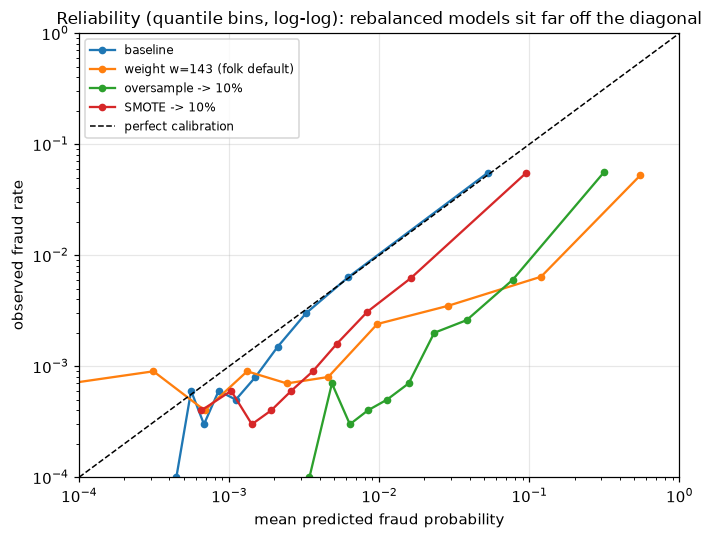

In [13]:
def reliability_bins(y, s, n_bins=10):
    edges = np.unique(np.quantile(s, np.linspace(0, 1, n_bins + 1)))
    bin_id = np.clip(np.searchsorted(edges, s, side="right") - 1, 0, len(edges) - 2)
    g = pd.DataFrame({"bin": bin_id, "s": s, "y": y}).groupby("bin")
    return g["s"].mean().to_numpy(), g["y"].mean().to_numpy()


fig, ax = plt.subplots(figsize=(6.5, 5))
for name in ["baseline", f"weight w={W_FULL:.0f} (folk default)", "oversample -> 10%", "SMOTE -> 10%"]:
    pred, obs = reliability_bins(y_te, runs[name][1])
    ok = obs > 0
    ax.plot(pred[ok], obs[ok], "o-", ms=4, label=name)
ax.plot([1e-4, 1], [1e-4, 1], "k--", lw=1, label="perfect calibration")
ax.set(xscale="log", yscale="log", xlim=(1e-4, 1), ylim=(1e-4, 1),
       title="Reliability (quantile bins, log-log): rebalanced models sit far off the diagonal",
       xlabel="mean predicted fraud probability", ylabel="observed fraud rate")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [14]:
odds = lambda p: p / (1 - p)
from_odds = lambda o: o / (1 + o)


def cal_row(s):
    return {"mean pred": s.mean(),
            "Brier x1000": 1000 * brier_score_loss(y_te, np.clip(s, 1e-7, 1 - 1e-7))}


cal = {}
specs = [
    (f"weight w={W_FULL:.0f} (folk default)", W_FULL, "divide"),
    (f"weight w={W_MATCH:.0f} (matched 10%)", W_MATCH, "divide"),
    ("undersample -> 10%", R_KEEP, "multiply"),
    ("oversample -> 10%", M_OVER, "divide"),
    ("SMOTE -> 10%", None, None),
]
cal["baseline (no repair needed)"] = {**cal_row(s_base), "mean pred fixed": np.nan, "Brier fixed": np.nan,
                                      "mean pred iso": np.nan, "Brier iso": np.nan}
for name, const, mode in specs:
    m, s = runs[name]
    row = cal_row(s)
    if mode is not None:
        o = odds(np.clip(s, 1e-9, 1 - 1e-9))
        s_fix = from_odds(o / const if mode == "divide" else o * const)
        row["mean pred fixed"], row["Brier fixed"] = s_fix.mean(), cal_row(s_fix)["Brier x1000"]
    else:
        row["mean pred fixed"], row["Brier fixed"] = np.nan, np.nan
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
    iso.fit(m.predict_proba(df_va[FEATURES])[:, 1], y_va)
    s_iso = iso.predict(s)
    row["mean pred iso"], row["Brier iso"] = s_iso.mean(), cal_row(s_iso)["Brier x1000"]
    cal[name] = row
cal_df = pd.DataFrame(cal).T
print(cal_df.round(4).to_string())
print(f"\ntest prevalence = {y_te.mean():.4f}")

                             mean pred  Brier x1000  mean pred fixed  Brier fixed  mean pred iso  Brier iso
baseline (no repair needed)     0.0070       5.9885              NaN          NaN            NaN        NaN
weight w=143 (folk default)     0.0716      35.5528           0.0024       6.3435         0.0070     6.2036
weight w=16 (matched 10%)       0.0359      15.2262           0.0054       6.2691         0.0068     6.2052
undersample -> 10%              0.0575      17.1960           0.0062       5.9219         0.0070     5.9038
oversample -> 10%               0.0503      14.7006           0.0052       5.9320         0.0069     5.7622
SMOTE -> 10%                    0.0136       6.1252              NaN          NaN         0.0069     5.8907

test prevalence = 0.0069


Three things to internalize:

- The raw rebalanced models predict 2–10x (weighting: up to 40x) the true fraud rate;
  Brier scores are up to ~6x the baseline's. The baseline needed no repair — log-loss
  boosting on the *true* prior is approximately calibrated for free.
- The analytic correction fixes most of the damage instantly and costs nothing — but it
  **overcorrects the weighted models** (mean pred lands *below* 0.7%). The formula is exact
  only if the learner fully internalized the weighted prior; an early-stopped GBM has not.
  Analytic correction is a first-order repair, not an identity.
- Isotonic on a held-out split repairs everything to the right mean, including SMOTE.
  It is monotone, so ranking metrics are untouched — verify, don't trust: check one AUC
  before/after if you're paranoid.

If you take one rule from this section: **if you rebalance for training, budget for
recalibration as part of the intervention** — the "free" PR-AUC point is not free.

## 5. The operating point: maximize caught dollars within review capacity

The model outputs probabilities; the business runs a queue. With calibrated $\hat p$ (the
baseline is calibrated out of the box — see above) and a \$5 review cost, the
*unconstrained* economic rule is: review any transaction where the expected recovery beats
the review cost, $\hat p \times \text{amount} > \$5$
(the general threshold algebra is in
[03_evaluation_calibration.ipynb](03_evaluation_calibration.ipynb)). First question: can
ops even staff that rule?

In [15]:
ev = s_base * amt_te                                  # expected $ recovered per review
alerts_econ = int((ev > C_REVIEW).sum())
print(f"unconstrained economic rule (p*amount > $5): {alerts_econ} alerts "
      f"= {alerts_econ / N_DAYS:.1f}/day  vs capacity {REVIEWS_PER_DAY}/day")

unconstrained economic rule (p*amount > $5): 1480 alerts = 16.4/day  vs capacity 10/day


The economics want more reviews than the team can do, so **the budget binds** and the
operating point becomes "the best $k$ = 900 alerts". Which ranking fills the queue best?
Ranking by $\hat p$ maximizes *count* recall; ranking by expected dollars
$\hat p \times \text{amount}$ maximizes *dollar* recall — and deprioritizes the
high-probability but near-worthless card-testing micro-charges. This is also where
calibration turns into money: with the SMOTE model's inflated raw scores,
$\hat p \times \text{amount}$ is mispriced and the same policy leaks value; after isotonic
repair it works again.

In [16]:
iso_sm = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
iso_sm.fit(runs["SMOTE -> 10%"][0].predict_proba(df_va[FEATURES])[:, 1], y_va)
s_smote_iso = iso_sm.predict(runs["SMOTE -> 10%"][1])


def policy_row(scores):
    top = np.argsort(-scores, kind="stable")[:K_BUDGET]
    caught = (amt_te[top] * y_te[top]).sum()
    return {"precision@900": y_te[top].mean(),
            "recall@900 (count)": y_te[top].sum() / y_te.sum(),
            "$recall@900": caught / TOTAL_FRAUD_DOLLARS,
            "net value $": caught - C_REVIEW * K_BUDGET}


policies = pd.DataFrame({
    "rank by p (baseline)": policy_row(s_base),
    "rank by p x amount": policy_row(s_base * amt_te),
    "rank by amount only": policy_row(amt_te.astype(float)),
    "rank by p x amount, SMOTE raw": policy_row(runs["SMOTE -> 10%"][1] * amt_te),
    "rank by p x amount, SMOTE isotonic": policy_row(s_smote_iso * amt_te),
    "oracle p x amount (ceiling)": policy_row(df_te["p_true"].to_numpy() * amt_te),
}).T
print(policies.round(3).to_string())

                                    precision@900  recall@900 (count)  $recall@900  net value $
rank by p (baseline)                        0.260               0.338        0.359     16726.73
rank by p x amount                          0.219               0.285        0.496     24865.92
rank by amount only                         0.020               0.026        0.198      7225.24
rank by p x amount, SMOTE raw               0.210               0.273        0.534     27075.01
rank by p x amount, SMOTE isotonic          0.221               0.288        0.513     25853.11
oracle p x amount (ceiling)                 0.283               0.368        0.598     30862.53


Same model, same budget: switching the queue from $\hat p$ to $\hat p \times \text{amount}$
trades a few points of count-recall for a large jump in dollars caught — usually the right
trade, *unless* card-testing micro-charges predict imminent large fraud on the same card,
in which case the value of catching them is not their amount (a modeling question about
labels and value attribution, not thresholds — raise it in the interview and you sound like
you've done this). The SMOTE-raw row shows miscalibration leaking real dollars under an
expected-value policy even though its PR-AUC was fine; isotonic repair recovers it.

The threshold view of the same decision: sweep $t$, watch value and alert volume together.

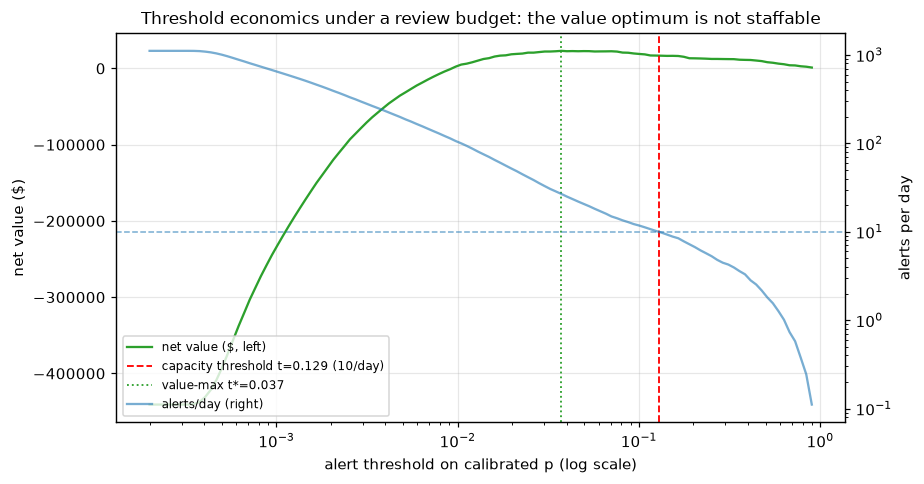

at capacity threshold 0.129: 10.0 alerts/day, net value $16,727
at value-max  threshold 0.037: 26.8 alerts/day, net value $23,023
-> the gap between those two rows is the business case for expanding review capacity
   (exercise 1 makes it precise)


In [17]:
ts = np.geomspace(2e-4, 0.9, 120)
alerts_day = np.array([(s_base >= t).sum() / N_DAYS for t in ts])
net_val = np.array([((amt_te * y_te)[s_base >= t]).sum() - C_REVIEW * (s_base >= t).sum() for t in ts])
t_budget = np.sort(s_base)[-K_BUDGET]                  # threshold implied by capacity
t_star = ts[np.argmax(net_val)]                        # unconstrained value-max threshold

fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.plot(ts, net_val, "C2", label="net value ($, left)")
ax1.axvline(t_budget, color="red", ls="--", lw=1.2,
            label=f"capacity threshold t={t_budget:.3f} (10/day)")
ax1.axvline(t_star, color="C2", ls=":", lw=1.2, label=f"value-max t*={t_star:.3f}")
ax1.set(xscale="log", xlabel="alert threshold on calibrated p (log scale)", ylabel="net value ($)",
        title="Threshold economics under a review budget: the value optimum is not staffable")
ax2 = ax1.twinx()
ax2.plot(ts, alerts_day, "C0", alpha=0.6, label="alerts/day (right)")
ax2.axhline(REVIEWS_PER_DAY, color="C0", ls="--", lw=1, alpha=0.6)
ax2.set_ylabel("alerts per day")
ax2.set_yscale("log")
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

mask_b = s_base >= t_budget
mask_s = s_base >= t_star
print(f"at capacity threshold {t_budget:.3f}: {mask_b.sum() / N_DAYS:.1f} alerts/day, "
      f"net value ${(amt_te * y_te)[mask_b].sum() - C_REVIEW * mask_b.sum():,.0f}")
print(f"at value-max  threshold {t_star:.3f}: {mask_s.sum() / N_DAYS:.1f} alerts/day, "
      f"net value ${(amt_te * y_te)[mask_s].sum() - C_REVIEW * mask_s.sum():,.0f}")
print("-> the gap between those two rows is the business case for expanding review capacity")
print("   (exercise 1 makes it precise)")

Notes a senior candidate should volunteer here:

- **The operating point is top-$k$, not a probability.** Under a binding capacity
  constraint, only the *ranking* matters for the count objective; the calibrated
  probabilities matter for the *value* objective ($\hat p \times \text{amount}$), for
  deciding whether capacity itself should grow, and for reporting.
- **Production fraud systems use two thresholds**: auto-block above $t_{hi}$ (no human,
  different cost matrix — false positives now decline good customers, which costs far more
  than \$5 of analyst time), human review in $[t_{lo}, t_{hi})$, waive below. Each
  threshold has its own economics.
- **Thresholds decay.** A probability threshold tuned this quarter encodes this quarter's
  prevalence and calibration; alert volume is the first thing to drift (section 6.3). Fix
  the *alert rate* (quantile), monitor the implied threshold, and recalibrate on a schedule.

## 6. Production reality: three ways the offline story breaks

### 6.1 Label delay and maturation

Fraud labels arrive by chargeback, typically 2–8 weeks after the transaction. At any
training snapshot, recent transactions have **immature** labels: fraud that hasn't been
reported yet is sitting in your table labeled 0. We simulate a gamma-distributed reporting
delay (mean ~36 days) against our 90-day window and look at what the label table claims at
snapshot time.

true train fraud rate 0.00693  |  observed at snapshot 0.00424  (636/1039 fraud labels matured)


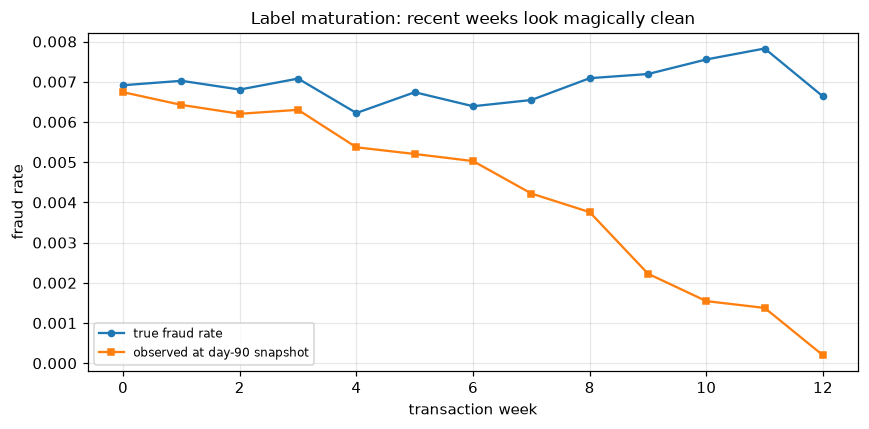

In [18]:
delay = rng.gamma(2.0, 18.0, len(df_tr))
matured = (df_tr["day"].to_numpy() + delay) <= N_DAYS
y_obs = y_tr * matured.astype(int)                     # what the label table shows today
print(f"true train fraud rate {y_tr.mean():.5f}  |  observed at snapshot {y_obs.mean():.5f}  "
      f"({y_obs.sum()}/{y_tr.sum()} fraud labels matured)")

week = df_tr["day"].to_numpy() // 7
rates = pd.DataFrame({"week": week, "true": y_tr, "observed": y_obs}).groupby("week").mean()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rates.index, rates["true"], "o-", ms=4, label="true fraud rate")
ax.plot(rates.index, rates["observed"], "s-", ms=4, label="observed at day-90 snapshot")
ax.set(title="Label maturation: recent weeks look magically clean",
       xlabel="transaction week", ylabel="fraud rate")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [19]:
m_naive = fit_lgbm(df_tr[FEATURES], y_obs)             # train on immature labels
mask_mature = df_tr["day"].to_numpy() < 45             # or: drop the immature tail
m_window = fit_lgbm(df_tr[FEATURES][mask_mature], y_obs[mask_mature])

mat = pd.DataFrame({
    "true labels (unobtainable)": {"PR-AUC": average_precision_score(y_te, s_base),
                                   "mean pred": s_base.mean()},
    "naive: all data, snapshot labels": {"PR-AUC": average_precision_score(y_te, score_test(m_naive)),
                                         "mean pred": score_test(m_naive).mean()},
    "matured window only (day<45)": {"PR-AUC": average_precision_score(y_te, score_test(m_window)),
                                     "mean pred": score_test(m_window).mean()},
}).T
print(mat.round(4).to_string())

                                  PR-AUC  mean pred
true labels (unobtainable)        0.2478     0.0070
naive: all data, snapshot labels  0.2100     0.0042
matured window only (day<45)      0.2049     0.0056


The damage comes in three layers: (1) the *monitored fraud rate* is understated ~40% at
snapshot time — dashboards celebrate a decline that is actually a reporting lag; (2)
training on immature labels poisons the freshest (most drift-relevant) data with
false negatives — ranking degrades and the model's mean prediction inherits the deflated
prior; (3) *evaluation* on immature labels flatters precision (unreported fraud in your
alert queue counts as a false positive... until it flips). Standard mitigations: train on a
maturation-lagged window (shown — recovers some ranking at the cost of discarding recent
data), weight labels by maturity $P(\text{reported by snapshot})$, and always **evaluate on
fully matured windows**. Monitoring implications continue in
[../10_ml_in_production/01_drift_monitoring.ipynb](../10_ml_in_production/01_drift_monitoring.ipynb).

### 6.2 Selective labels: the model erases its own training signal

Two flavors, both feedback loops:

- **Review-queue flavor**: analysts label only what gets alerted; everything below
  threshold is assumed legit. Your next training set's labels are censored by your current
  model's opinions.
- **Blocking flavor** (demonstrated below): transactions the model **auto-blocks never
  happen**, so they can never produce a chargeback label. The better your model, the faster
  the patterns it catches vanish from your training data — next quarter's model is trained
  on a world where your best signal appears fraud-free.

We deploy the baseline as gen-1, auto-block the top 1% on a fresh quarter of traffic,
train gen-2 only on the approved (labelable) traffic, and compare against the
counterfactual gen-2 trained with full labels. We also try the textbook mitigation:
**exploration** — let through a random 10% of would-be-blocks and weight them by
1/0.1 = 10 (inverse propensity weighting, exactly the estimator family of
[../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb](../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb)).

In [20]:
df_new = simulate_transactions(150_000, rng)           # next quarter's traffic
y_new = df_new["is_fraud"].to_numpy()
s_new = m_base.predict_proba(df_new[FEATURES])[:, 1]
BLOCK_RATE = 0.01
t_block = np.quantile(s_new, 1 - BLOCK_RATE)
blocked = s_new >= t_block
print(f"gen-1 auto-blocks {blocked.sum():,} txns (top {BLOCK_RATE:.0%}), containing "
      f"{y_new[blocked].sum()} of {y_new.sum()} frauds ({y_new[blocked].sum() / y_new.sum():.0%}) "
      f"-> those labels never exist")

EPS = 0.10
explore = blocked & (rng.random(len(df_new)) < EPS)    # let-through exploration slice
kept = ~blocked | explore
w_ipw = np.where(explore[kept], 1 / EPS, 1.0)

gen2 = {}
for name, X_fit, y_fit, sw in [
    ("gen-2, full labels (counterfactual)", df_new[FEATURES], y_new, None),
    ("gen-2, censored by gen-1 blocking", df_new[FEATURES][~blocked], y_new[~blocked], None),
    (f"gen-2, censored + {EPS:.0%} exploration (IPW)", df_new[FEATURES][kept], y_new[kept], w_ipw),
]:
    m = fit_lgbm(X_fit, y_fit, sample_weight=sw)
    s = score_test(m)
    top = np.argsort(-s, kind="stable")[:K_BUDGET]
    gen2[name] = {"PR-AUC": average_precision_score(y_te, s),
                  "recall@900": y_te[top].sum() / y_te.sum()}
print(pd.DataFrame(gen2).T.round(3).to_string())

gen-1 auto-blocks 1,500 txns (top 1%), containing 390 of 1065 frauds (37%) -> those labels never exist


                                         PR-AUC  recall@900
gen-2, full labels (counterfactual)       0.231       0.351
gen-2, censored by gen-1 blocking         0.189       0.319
gen-2, censored + 10% exploration (IPW)   0.199       0.318


Censoring just 1% of traffic — but ~1/3 of the *fraud* — measurably degrades the next
generation, and note that in production you could not even see this table: your offline
eval set is censored the same way, so gen-2 would look *fine* on it. The exploration slice
only partially repairs the damage at this scale: a 10% let-through of a 1% block region is
~150 transactions, and IPW's small-$\varepsilon$/large-weight variance is exactly the
pathology the causal-inference notebook dissects. The realistic mitigation stack: keep an
always-on randomized holdout/exploration slice (price it as the cost of measurement), use
label sources that flow regardless of your decisions (issuer chargebacks on *approved*
traffic, consortium data), and treat "our blocked traffic has no outcomes" as a permanent
structural fact of the system — not a data bug someone will fix.

### 6.3 Adversarial drift

Fraud is the one domain where the data-generating process *fights back*: fraudsters probe
the boundary and reallocate toward whatever you don't catch. We simulate next quarter's
adaptation — device spoofing (new-device signal weakens), no more card-testing
micro-charges, daytime activity — with total fraud volume unchanged.

In [21]:
COEF_ADAPT = {**COEF, "new_device": 0.6, "device_burst": 0.5, "micro": 0.0,
              "night": 0.15, "cb_night": 0.3, "burst": 0.6}
df_drift = simulate_transactions(100_000, rng, coef=COEF_ADAPT)
y_dr = df_drift["is_fraud"].to_numpy()
s_dr = m_base.predict_proba(df_drift[FEATURES])[:, 1]
top_dr = np.argsort(-s_dr, kind="stable")[:K_BUDGET]

drift_tbl = pd.DataFrame({
    "test window (stationary)": {"fraud rate": y_te.mean(),
                                 "PR-AUC": average_precision_score(y_te, s_base),
                                 "recall@900": protocol(s_base)["recall@900"],
                                 "alerts/day @ old threshold": (s_base >= t_budget).sum() / N_DAYS},
    "next quarter (adapted fraud)": {"fraud rate": y_dr.mean(),
                                     "PR-AUC": average_precision_score(y_dr, s_dr),
                                     "recall@900": y_dr[top_dr].sum() / y_dr.sum(),
                                     "alerts/day @ old threshold": (s_dr >= t_budget).sum() / N_DAYS},
}).T
print(drift_tbl.round(3).to_string())

                              fraud rate  PR-AUC  recall@900  alerts/day @ old threshold
test window (stationary)           0.007   0.248       0.338                      10.000
next quarter (adapted fraud)       0.007   0.112       0.227                       9.878


Same fraud volume, same features, same model — recall at the budget drops by a third and
PR-AUC halves, while the *input distributions barely move* (fraud is 0.7% of traffic; the
adaptation is invisible in aggregate feature drift). This is why fraud monitoring leans on
**label-based and rank-based** signals — matured precision@k by cohort, alert-volume at a
fixed threshold, score distribution of *confirmed* fraud — rather than generic feature-PSI
dashboards, and why retraining cadence is a first-class design parameter. The monitoring
machinery is built in
[../10_ml_in_production/01_drift_monitoring.ipynb](../10_ml_in_production/01_drift_monitoring.ipynb).

## 7. Pitfalls

### Pitfall 1 — resampling before the split

The single most common imbalance bug: apply SMOTE (or duplication) to the *whole* dataset,
then split. Synthetic points are interpolations of real ones — after splitting, the model
holds points interpolated from (or duplicated into) its own validation fold. Validation
metrics inflate to fantasy levels; the test set (or worse, production) tells the truth
later. Same leakage family as
[02_leakage_validation.ipynb](02_leakage_validation.ipynb), imbalance edition.

In [22]:
# WRONG: SMOTE the training pool first, split afterwards
X_synth_wrong = smote_synthesize(X_tr_np[pos_idx], n_synth, rng)
X_wrong = np.vstack([X_tr_np, X_synth_wrong])
y_wrong = np.concatenate([y_tr, np.ones(n_synth, dtype=int)])
perm = rng.permutation(len(y_wrong))
cut = int(0.75 * len(y_wrong))
fit_i, val_i = perm[:cut], perm[cut:]
m_leak = fit_lgbm(pd.DataFrame(X_wrong[fit_i], columns=FEATURES), y_wrong[fit_i])
val_pr = average_precision_score(y_wrong[val_i],
                                 m_leak.predict_proba(pd.DataFrame(X_wrong[val_i], columns=FEATURES))[:, 1])
test_pr = average_precision_score(y_te, score_test(m_leak))

hon_val = average_precision_score(y_va, runs["SMOTE -> 10%"][0].predict_proba(df_va[FEATURES])[:, 1])
hon_test = bakeoff.loc["SMOTE -> 10%", "PR-AUC"]
cmp = pd.DataFrame({
    "SMOTE before split (WRONG)": {"validation PR-AUC": val_pr, "test PR-AUC": test_pr},
    "SMOTE after split (correct)": {"validation PR-AUC": hon_val, "test PR-AUC": hon_test},
}).T
print(cmp.round(3).to_string())

                             validation PR-AUC  test PR-AUC
SMOTE before split (WRONG)               0.935        0.240
SMOTE after split (correct)              0.221        0.248


The broken pipeline reports a validation PR-AUC near 1.0 — a ~4x overstatement of reality.
This number gets into slide decks. The correct pipeline's validation score agrees with
test. Rule: **resampling is a training-only transform**; it never touches validation, test,
or anything used for early stopping, calibration, or threshold selection.

### Pitfall 2 — evaluating on a rebalanced test set

A cousin of Pitfall 1: benchmark suites (and papers) that report metrics on a 50/50
rebalanced test set. Precision-family metrics depend on prevalence, so this answers a
question about a world with 70x your fraud rate.

In [23]:
bal_idx = np.concatenate([np.where(y_te == 1)[0],
                          rng.choice(np.where(y_te == 0)[0], y_te.sum(), replace=False)])
top100_bal = np.argsort(-s_base[bal_idx], kind="stable")[:100]
top100 = np.argsort(-s_base, kind="stable")[:100]
print(f"same model, PR-AUC:  balanced test {average_precision_score(y_te[bal_idx], s_base[bal_idx]):.3f}   "
      f"real test {average_precision_score(y_te, s_base):.3f}")
print(f"same model, precision@100:  balanced test {y_te[bal_idx][top100_bal].mean():.2f}   "
      f"real test {y_te[top100].mean():.2f}")

same model, PR-AUC:  balanced test 0.936   real test 0.248
same model, precision@100:  balanced test 0.99   real test 0.60


Both numbers are "true"; only one describes your queue. Report metrics at deployment
prevalence, and never compare PR-AUCs across datasets or periods with different base rates
without saying so (a random ranker's PR-AUC *equals* the prevalence).

### Pitfall 3 — shipping the default 0.5 threshold

`predict()` thresholds at 0.5 for every sklearn-style classifier. At 0.7% prevalence that
default is wrong in *both* directions depending on training scheme:

In [24]:
for name in ["baseline", f"weight w={W_FULL:.0f} (folk default)"]:
    s = runs[name][1]
    n_alert = int((s >= 0.5).sum())
    rec = y_te[s >= 0.5].sum() / y_te.sum()
    print(f"{name:34s} threshold 0.5 -> {n_alert / N_DAYS:6.1f} alerts/day  "
          f"(capacity {REVIEWS_PER_DAY}), recall {rec:.3f}")

baseline                           threshold 0.5 ->    2.0 alerts/day  (capacity 10), recall 0.137
weight w=143 (folk default)        threshold 0.5 ->   57.6 alerts/day  (capacity 10), recall 0.650


The calibrated baseline at 0.5 almost never alerts (nearly no transaction is >50% fraud);
the weighted model at 0.5 buries the ops team ~6x over capacity. Neither number came from
the economics. The threshold is an output of the cost matrix and the capacity constraint
(section 5), never a library default — and after any rebalancing, "0.5" doesn't even mean
what it appears to mean (section 4).

## 8. Interview corner

**Q1. Dataset with 1% positives — walk me through your approach.**
Strong answer, in order: (1) pin down the *decision* the model feeds (review queue?
auto-block? budget? costs per FP/FN?) — that defines the metrics; (2) evaluation protocol
first: stratified or time-based splits as the data demands, PR-AUC plus
precision/recall@budget and a value metric, never accuracy, ROC-AUC only as a secondary
summary; (3) strong tabular baseline (boosted trees) with early stopping on PR-AUC —
1% × large n is often plenty of positives; (4) try weighting/resampling as *hyperparameters*
under the frozen protocol, expect small effects, check seeds; (5) calibrate (rebalancing
breaks it, and the policy consumes probabilities); (6) threshold from economics + capacity,
not 0.5; (7) name production risks: label delay, selective labels, drift. Mentioning that
feature work dominates resampling work is a senior marker.

**Q2. Does SMOTE help?**
Strong answer: know what it does (interpolate minority neighbors), when it can help (weak
or distance-based learners, small genuinely-continuous data), and why it usually doesn't
on modern tabular stacks: strong learners extract the same boundary information from the
real points; interpolation manufactures impossible rows with mixed/binary features
(fractional flags); benchmarks (e.g. "To SMOTE, or not to SMOTE?", 2022) find no gain over
proper baselines with boosted trees — matching what we saw (SMOTE ≤ naive duplication).
Plus two taxes: it breaks calibration, and misapplied (before the split) it fabricates
validation performance. Answering "SMOTE" *first* to Q1 is how you fail Q1.

**Q3. How do you set the alert threshold?**
Strong answer: it's not a model property. Elicit review cost, loss-given-fraud, and
capacity. Unconstrained: alert when expected saving beats review cost
($\hat p \cdot \text{amount} > c$ — requires *calibrated* $\hat p$). If capacity binds
(it usually does), the operating point is top-$k$ by expected value within the budget; the
"threshold" is just the $k$-th score. Operate on alert *rate*, monitor volume drift,
re-derive after prevalence shifts, and distinguish the review threshold from any
auto-block threshold (different cost matrix; blocking FPs decline good customers).

**Q4. What is the selective labels problem?**
Strong answer: outcomes are observed conditional on the *current policy's* decisions —
blocked transactions never generate chargebacks, un-alerted cases never get analyst labels
(same structure as loan approvals: no default outcome for rejected applicants). Consequences:
next-generation training data is censored exactly where the current model is confident, the
feedback loop compounds across generations, and offline evaluation is blind to it because
eval data is censored identically. Mitigations: randomized let-through/exploration traffic
with IPW correction (mind the small-$\varepsilon$ variance), decision-independent label
sources, and explicit measurement holdouts. Naming the eval-blindness part is what
separates senior answers.

**Q5. Why is ROC-AUC misleading at extreme imbalance, and what do you report?**
Strong answer: ROC's FPR axis divides by the enormous negative count, so operationally
catastrophic false-positive volumes look tiny; ROC-AUC is also prevalence-invariant, hiding
exactly the thing that hurts. Report the PR view (prevalence-sensitive), metrics at the
operating point (precision@budget, recall@budget, value), and give precision numbers with
their prevalence. Bonus: precision is computable from (TPR, FPR, π) — the curves carry the
same information, weighted differently — and a random ranker's PR-AUC equals prevalence, so
PR-AUC comparisons across base rates are meaningless.

**Q6. Offline metrics are great; production catches little. What do you check?**
Strong answer, as a checklist: leakage in offline features (future info, post-decision
fields); label maturity — was the model trained/evaluated on immature windows?; prevalence
or mix shift moving the threshold's implied alert volume; adversarial adaptation
(score distribution of confirmed fraud drifting down); the selective-labels loop (offline
eval censored by the incumbent policy); calibration decay. Then: matured-window
re-evaluation, cohort-based monitoring, exploration traffic, retraining cadence.

**Q7. Product asks: "just retrain on a 50/50 balanced sample." What happens?**
Strong answer: ranking will barely change (maybe a small gain or loss — measure under a
frozen protocol with seed replicates), but every predicted probability becomes wrong by
roughly the odds ratio (~70x here at the extreme), so thresholds, expected-value queues,
and any dollar reporting silently break unless you recalibrate or apply the analytic prior
correction. Also flag the operational tax: more training pipeline states to maintain. If
compute on the negative class is the real problem, undersample + correct the intercept —
and validate the whole thing end-to-end at the operating point.

## 9. Key takeaways

- At 0.5–1% prevalence, evaluation comes first: accuracy is prevalence in disguise,
  ROC-AUC hides the false-positive flood, and the metrics that matter are PR-AUC plus
  **precision/recall/value at the ops review budget**.
- Even a perfect model has modest precision under heavy class overlap — the oracle's
  PR-AUC here is ~0.40. Calibrate stakeholder expectations from a ceiling estimate, not
  from hope.
- Under one frozen protocol, rebalancing interventions moved metrics by a couple of points
  at most: mild resampling edged out the baseline, **SMOTE lost to naive duplication**, and
  cost-sensitive weighting underperformed — with seed-level instability comparable to the
  effects themselves. The intervention axis is small; the feature axis is large.
- "Weighting ≡ oversampling because the loss is identical" is false in practice —
  implementation details (binning, bagging, early stopping) break the equivalence. Validate
  rebalancing knobs empirically; import no conclusions.
- Every rebalancing scheme trains under a fake prior and **destroys calibration**
  (mean predictions 2–40x the true rate). Analytic prior correction is a good first-order
  repair (odds $/w$ or $\times r$) but overcorrects early-stopped GBMs; isotonic on held-out
  data fixes everything and preserves ranking. Budget recalibration into any rebalancing
  decision.
- The operating point is an economics-and-capacity problem: unconstrained rule
  $\hat p \cdot \text{amount} > c$; when the review budget binds, top-$k$ by expected
  dollars. Ranking by $\hat p \times \text{amount}$ traded ~5pp of count-recall for ~14pp
  of dollar-recall here.
- Labels mature late (chargebacks): snapshot fraud rates are understated, fresh training
  data is silently mislabeled, and evaluation must use matured windows.
- Selective labels: your own blocking censors your future training data *and* your offline
  evaluation — pay for exploration/holdout traffic or inherit your current model's blind
  spots forever.
- Fraud drifts adversarially: the model's targets adapt to it. Monitor matured precision by
  cohort and alert volume at fixed thresholds; generic feature-drift dashboards can miss a
  0.7%-of-traffic adversary entirely.

## Exercises

**Exercise 1 — the business case for more reviewers.** Using calibrated baseline scores,
rank test transactions by expected recovered dollars $\hat p_i \cdot \text{amount}_i$.
(a) Find the optimal review volume $k^*$: the point where the *expected* marginal alert
stops paying for its \$5 review. (b) Compute realized net value at $k^*$ vs at the current
budget (900), and state the value of expanding capacity in $/quarter. (c) Why should you
quote the *expected* (model-based) value with a caveat, not the realized number?

**Exercise 2 — the weight is a hyperparameter.** Sweep
`scale_pos_weight` ∈ {1, 4, 16, 64, 143}. Plot test PR-AUC and mean predicted probability
against $w$ (log axis). Where is ranking best? What happens to calibration as $w$ grows,
and at what $w$ would the analytic correction $\text{odds}/w$ be exactly right?

**Exercise 3 — undersampling without the information loss.** Single 10%-undersampling
discards ~94% of negatives. Build a small ensemble instead: 5 LightGBMs, each on all
positives + an independent 10%-prevalence draw of negatives; average their scores. Compare
PR-AUC and recall@900 against the single undersampled model and the baseline. Why does
averaging help, and what production cost does it add?

(a) k* = 1480 alerts (~16.4/day) — expected marginal value crosses $0 there
(b) realized net value @ k*=1480: $27,359   @ budget k=900: $24,866
    -> expanding review capacity from 10/day to ~16/day is worth ~$2,493 per quarter (before hiring costs)
(c) The realized number is one noisy draw and is only visible in hindsight; the
    expected number is what the calibrated model can forecast *before* staffing —
    but it inherits any calibration error, so quote it with a matured-label backtest.


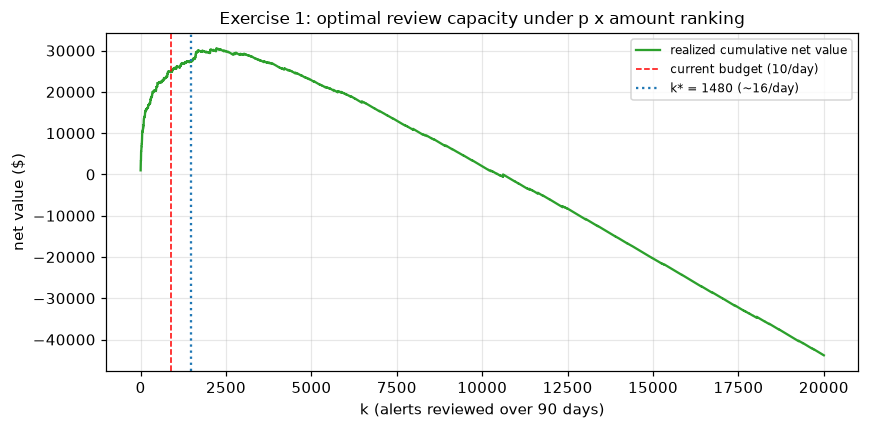

In [25]:
# --- Solution 1 ---
ev_order = np.argsort(-(s_base * amt_te), kind="stable")
exp_marginal = (s_base * amt_te)[ev_order] - C_REVIEW          # expected net $ of k-th alert
k_star = int(np.searchsorted(-exp_marginal, 0))                # first k where it goes negative
real_cum = np.cumsum((amt_te * y_te)[ev_order]) - C_REVIEW * np.arange(1, len(y_te) + 1)

print(f"(a) k* = {k_star} alerts (~{k_star / N_DAYS:.1f}/day) — expected marginal value "
      f"crosses $0 there")
print(f"(b) realized net value @ k*={k_star}: ${real_cum[k_star - 1]:,.0f}   "
      f"@ budget k=900: ${real_cum[K_BUDGET - 1]:,.0f}")
print(f"    -> expanding review capacity from 10/day to ~{k_star / N_DAYS:.0f}/day is worth "
      f"~${real_cum[k_star - 1] - real_cum[K_BUDGET - 1]:,.0f} per quarter (before hiring costs)")
print("(c) The realized number is one noisy draw and is only visible in hindsight; the")
print("    expected number is what the calibrated model can forecast *before* staffing —")
print("    but it inherits any calibration error, so quote it with a matured-label backtest.")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, 20001), real_cum[:20000], "C2", label="realized cumulative net value")
ax.axvline(K_BUDGET, color="red", ls="--", lw=1, label="current budget (10/day)")
ax.axvline(k_star, color="C0", ls=":", lw=1.5, label=f"k* = {k_star} (~{k_star / N_DAYS:.0f}/day)")
ax.set(title="Exercise 1: optimal review capacity under p x amount ranking",
       xlabel="k (alerts reviewed over 90 days)", ylabel="net value ($)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

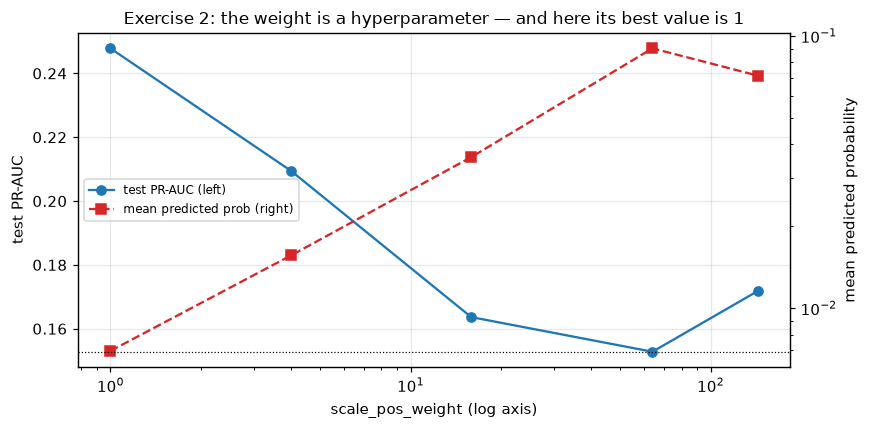

       w  PR-AUC  mean pred
  1.0000  0.2478     0.0070
  4.0000  0.2094     0.0156
 15.9300  0.1636     0.0359
 64.0000  0.1528     0.0901
143.3696  0.1718     0.0716

Ranking is best at w = 1 on this data; mean prediction inflates roughly linearly in w
(dotted line = true prevalence 0.0069). The analytic odds/w correction is exact
only if the learner fully absorbed the weighted prior — true for converged logistic
regression, only approximate for early-stopped boosting (section 4).


In [26]:
# --- Solution 2 ---
w_grid = [1.0, 4.0, W_MATCH, 64.0, W_FULL]
pr_w, mp_w = [], []
for w in w_grid:
    if w == 1.0:
        s = s_base
    elif w == W_MATCH:
        s = runs[f"weight w={W_MATCH:.0f} (matched 10%)"][1]
    elif w == W_FULL:
        s = runs[f"weight w={W_FULL:.0f} (folk default)"][1]
    else:
        s = score_test(fit_lgbm(df_tr[FEATURES], y_tr, scale_pos_weight=w))
    pr_w.append(average_precision_score(y_te, s))
    mp_w.append(s.mean())

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(w_grid, pr_w, "o-", color="C0", label="test PR-AUC (left)")
ax1.set(xscale="log", xlabel="scale_pos_weight (log axis)", ylabel="test PR-AUC",
        title="Exercise 2: the weight is a hyperparameter — and here its best value is 1")
ax2 = ax1.twinx()
ax2.plot(w_grid, mp_w, "s--", color="C3", label="mean predicted prob (right)")
ax2.axhline(y_te.mean(), color="k", lw=0.8, ls=":")
ax2.set_ylabel("mean predicted probability")
ax2.set_yscale("log")
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8, loc="center left")
fig.tight_layout()
plt.show()
print(pd.DataFrame({"w": w_grid, "PR-AUC": pr_w, "mean pred": mp_w}).round(4).to_string(index=False))
print(f"\nRanking is best at w = 1 on this data; mean prediction inflates roughly linearly in w")
print(f"(dotted line = true prevalence {y_te.mean():.4f}). The analytic odds/w correction is exact")
print("only if the learner fully absorbed the weighted prior — true for converged logistic")
print("regression, only approximate for early-stopped boosting (section 4).")

In [27]:
# --- Solution 3 ---
bag_scores = []
for b in range(5):
    neg_b = rng.choice(neg_idx, n_neg_keep, replace=False)
    bi = np.concatenate([pos_idx, neg_b])
    m_b = fit_lgbm(df_tr[FEATURES].iloc[bi], y_tr[bi], random_state=100 + b)
    bag_scores.append(score_test(m_b))
s_bag = np.mean(bag_scores, axis=0)

sol3 = pd.DataFrame({
    "single undersample -> 10%": {"PR-AUC": bakeoff.loc["undersample -> 10%", "PR-AUC"],
                                  "recall@900": bakeoff.loc["undersample -> 10%", "recall@900"]},
    "undersample bag (5 draws)": {"PR-AUC": average_precision_score(y_te, s_bag),
                                  "recall@900": protocol(s_bag)["recall@900"]},
    "baseline (all data)": {"PR-AUC": bakeoff.loc["baseline", "PR-AUC"],
                            "recall@900": bakeoff.loc["baseline", "recall@900"]},
}).T
print(sol3.round(3).to_string())
print("\nEach draw sees a different 6% of negatives, so averaging cancels the variance a single")
print("draw suffers from discarding 94% of the majority class (an EasyEnsemble-style trick;")
print("each member trains on ~10k rows, so the 5 fits are cheap). Costs: 5 models to version,")
print("serve, and monitor — and the averaged score needs its own calibration pass before any")
print("probability-consuming policy (section 4).")

                           PR-AUC  recall@900
single undersample -> 10%   0.246       0.379
undersample bag (5 draws)   0.276       0.389
baseline (all data)         0.248       0.338

Each draw sees a different 6% of negatives, so averaging cancels the variance a single
draw suffers from discarding 94% of the majority class (an EasyEnsemble-style trick;
each member trains on ~10k rows, so the 5 fits are cheap). Costs: 5 models to version,
serve, and monitor — and the averaged score needs its own calibration pass before any
probability-consuming policy (section 4).
